#### Background

The card game Flip 7 is a push-your-luck game. The deck has cards numbered 0 through 12. The number on each card indicates its point value and also the number of those cards in the deck (except for the 0 card, of which there is one). This means there are twelve 12s, eleven 11s, etc.

On the first turn of each round, the dealer deals one card to each player. On subsequent turns, each players chooses to hit or stay. If they hit, the dealer deals them one additional card. If the card is a duplicate, the player busts and exits the round with zero points. If they stay, they exit the round and add the sum of their cards to their point total from previous rounds.

If a player ever has seven unique cards, the round ends immediately for all players. Each player who didn't bust adds the sum of their cards to their point total and the player with seven cards scores a bonus 15 points.

The game ends when at least one player has 200 points at the end of a round. The winner is the player with the most points.

#### Instructions

Write a code to to test Flip 7 stratgies. Use a random 32-bit seed. Run separate simulations for each of two players using at least $N$ = 10,000 trials. Start each trial with a fresh, shuffled deck. Players use the following strategies:

- Player A: hits when their score for the round is < 30 and stays when their round score is $\ge$ 30
- Player B: hits when they have 0 or 1 card with value $\ge$ 9 and stays when they have 2 cards $\ge$ 9

Track each player's points per round. Plot a histogram of your results. Report the average $\mu \pm \sigma_m$ and the standard deviation $\sigma$. Estimate the error in the mean as

$$
\sigma_m = \frac{\sigma}{\sqrt{N}}
$$

Also report the percentage of rounds that end with a bust, a stay, or a bonus.

#### Example A
In round 1, player A gets a 12, then hits and gets another 12. They bust and score 0 points. 
In round 2, A gets a 10, then hits three times, receiving a 9, 7, 4. They stay because their hand sums to 30.
In round 3, A gets a 5, then hits four times, receiving 8, 12, 1, 11. They stay because their hand sums to 37.
In round 4, A gets a 10, then hits twice, receiving 8, 10. They bust and score 0 points.

| Score | Round | Hand        | Result |
| ----- | ----- | ----------- | ------ |
|    -- |     1 | 12 12       | bust   |
|     0 |     2 | 10 9 7 4    | stay   |
|    30 |     3 | 5 8 12 1 11 | stay   |
|    67 |     4 | 10 8 10     | bust   |
|    67 |

#### Example B

For the same sequence of cards, player B gets a different score. In round 1, player B gets a 12, then hits and gets another 12. They bust and score 0 points.
In round 2, B gets a 10, then hits, receiving a 9. They stay because they have two cards $\ge$ 9. They score 19 points.
In round 3, B gets a 7, then hits six times, receiving a 4, 5, 8, 12, 1, 11. Since they have 7 unique cards, the round automatically ends. The score 48 points from their cards and a 15 point bonus.
In round 4, B gets a 10, then hits twice, receiving 8, 10. They bust and score 0 points.

| Score | Round | Hand            | Result |
| ----- | ----- | ----------------| ------ |
|    -- |     1 | 12 12           | bust   |
|     0 |     2 | 10 9            | stay   |
|    19 |     3 | 7 4 5 8 12 1 11 | bonus  |
|    82 |     4 | 10 8 10         | bust   |
|    82 |

#### Sample Output

Sample output, for different strategies, is

```
seed = 238647638663900449

Number of trials: 100000

Player A: Stay at 20 points
  Points:
    average: 18.3 +/- 0.0329
    st dev:  10.4
  stay:  76.7
  bust:  23.3
  bonus:  0.0

Player B: Always hit
  Points:
    average: 5.7 +/- 0.0591
    st dev:  18.7
  stay:   0.0
  bust:  91.4
  bonus:  8.6
```

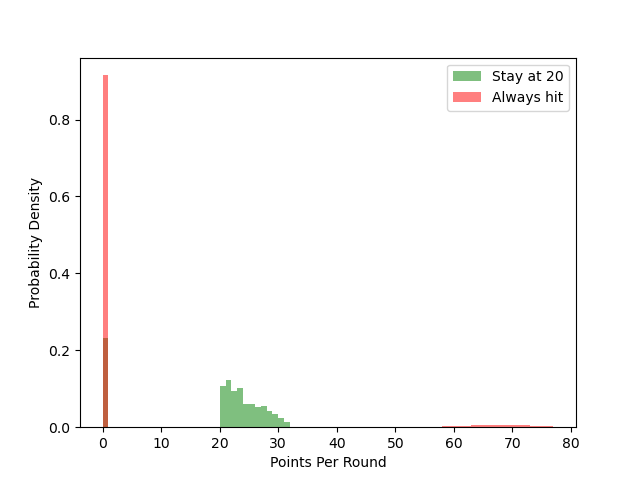

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
seed = np.random.default_rng().integers(int(2**63))
print('seed = %d' % seed)
rng = np.random.default_rng(seed=seed)

seed = 5588308460060099238


seed = 5588308460060099238
Number of Trials = 10000

Player A: hits when their score for the round is < 30 and stays when their round score is >= 30
Points:
     Average: 15.5 +/- 0.1499
     st dev = 14.99
Stays:  45.94
Busts:  53.95
Bonus:  0.11


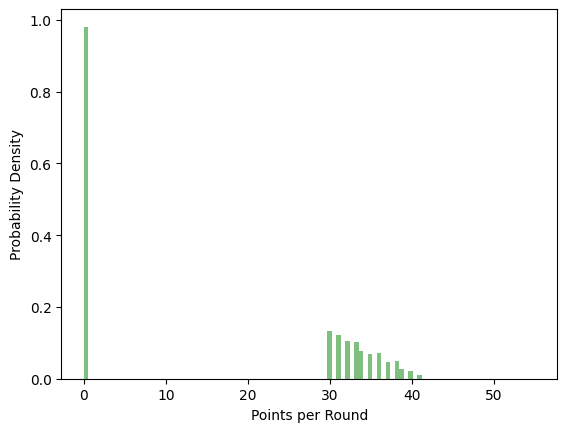

In [7]:
## Player A ##

# define constants

nTrials = 10000 # START with 100 first 
nFlips = 7  # Reaches 7 unique cards, round end immediately and bonus points hit 

cards = [0,1,2,3,4,5,6,7,8,9,10,11,12]
probabilities = np.array([0.0127,0.0127,0.0253,0.038,0.0506,0.0633,0.0759,0.0886,0.101,0.114,0.127,0.139,0.1519])

# main code

Total_Score=0
Stays = 0
Bust = 0
Bonus = 0
All_Scores_A=[]

for iTrial in range(nTrials):
    score = 0
    probabilities = probabilities
    oCards = 0
    Cards = []

    for iFlip in range(nFlips):
        iCards = rng.choice(cards,p=probabilities)

        #  index = cards.index(iCards)
        #  probabilities = np.array([x*(79/(79-iFlip)) for x in probabilities])  # adjust the probablities for all the other cards based on the card removed
        #  probabilities[index] = (index-1)/(79-iFlip) # adjust the probablities for that specific card number removed

        ### Was not able to get the probabilies to readjust after each flip, kept getting error ###

        if iCards in Cards:
            score = 0 
            Bust += 1
            break
        else:
            Cards.append(iCards)
        
        score += iCards

        if len(Cards) == nFlips:
            Bonus += 1
            score += 15 
            break

        if score >= 30:
            Stays += 1 
            break

    Total_Score += score
    All_Scores_A.append(score)

avg = Total_Score/nTrials
std = np.sqrt(abs(avg-avg**2))
        

print('seed = %d' % seed)
print('Number of Trials =', nTrials)
print()
print('Player A: hits when their score for the round is < 30 and stays when their round score is >= 30')
print('Points:')
print('     Average: %.4g +/- %.4g' % (avg,std/np.sqrt(nTrials)))
print('     st dev = %.4g' % std)
print('Stays: ', 100*Stays/nTrials)
print('Busts: ', 100*Bust/nTrials)
print('Bonus: ', 100*Bonus/nTrials)

plt.hist(All_Scores_A, 100, density=1, facecolor='g', edgecolor = 'none', alpha=0.5)
plt.ylabel('Probability Density')
plt.xlabel('Points per Round')
plt.show()


seed = 5588308460060099238
Number of Trials = 10000

Player B: hits when they have 0 or 1 card with value >= 9 and stays when they have 2 cards >= 9
Points:
     Average: 16.61 +/- 0.1611
     st dev = 16.11
Stays:  0
Busts:  3921
Bonus:  56


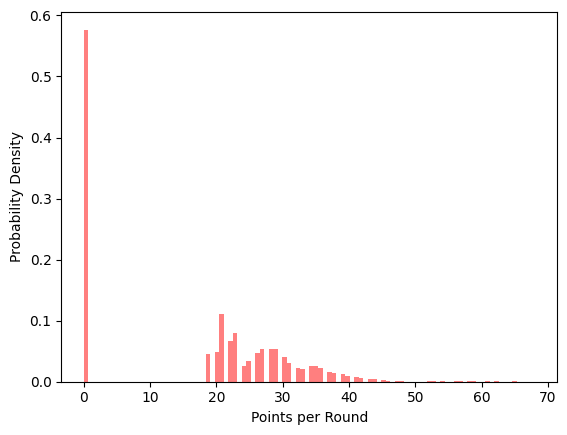

In [8]:
## Player B ##

# define constants

nTrials = 10000 # START with 100 first 
nFlips = 7  # Reaches 7 unique cards, round end immediately and bonus points hit 

cards = [0,1,2,3,4,5,6,7,8,9,10,11,12]
probabilities = np.array([0.0127,0.0127,0.0253,0.038,0.0506,0.0633,0.0759,0.0886,0.101,0.114,0.127,0.139,0.1519])

# main code

Total_Score=0
Stays = 0
Bust = 0
Bonus = 0
All_Scores_B=[]

for iTrial in range(nTrials):
    score = 0
    probabilities = probabilities
    oCards = 0
    high_Cards = 0
    Cards = []

    for iFlip in range(nFlips):
        iCards = rng.choice(cards,p=probabilities)

        if iCards in Cards:
            score = 0 
            Bust += 1
            break
        else:
            Cards.append(iCards)
        
        score += iCards

        if len(Cards) == nFlips:
            Bonus += 1
            score += 15 
            break
        
        if iCards >= 9:
            high_Cards += 1 
            if high_Cards >= 2:
                break


    Total_Score += score
    All_Scores_B.append(score)

avg = Total_Score/nTrials
std = np.sqrt(abs(avg-avg**2))
        

print('seed = %d' % seed)
print('Number of Trials =', nTrials)
print()
print('Player B: hits when they have 0 or 1 card with value >= 9 and stays when they have 2 cards >= 9')
print('Points:')
print('     Average: %.4g +/- %.4g' % (avg,std/np.sqrt(nTrials)))
print('     st dev = %.4g' % std)
print('Stays: ', Stays)
print('Busts: ', Bust)
print('Bonus: ', Bonus)

plt.hist(All_Scores_B, 100, density=1, facecolor='r', edgecolor = 'none', alpha=0.5)
plt.ylabel('Probability Density')
plt.xlabel('Points per Round')
plt.show()

seed = 5588308460060099238
Number of Trials = 10000

Player A: hits when their score for the round is < 30 and stays when their round score is >= 30
Points:
     Average: 15.46 +/- 0.1495
     st dev = 14.95
Stays:  45.83
Busts:  54.08
Bonus:  0.09

Player B: hits when they have 0 or 1 card with value >= 9 and stays when they have 2 cards >= 9
Points:
     Average: 16.5 +/- 0.16
     st dev = 16
Stays:  0
Busts:  3980
Bonus:  72


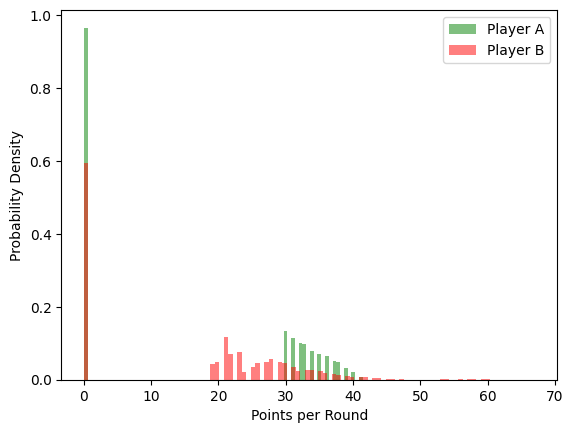

In [9]:
### Combined in order to plot both together ###
###############################################

## Player A ##

# define constants

nTrials = 10000 # START with 100 first 
nFlips = 7  # Reaches 7 unique cards, round end immediately and bonus points hit 
cards = [0,1,2,3,4,5,6,7,8,9,10,11,12]
probabilities = np.array([0.0127,0.0127,0.0253,0.038,0.0506,0.0633,0.0759,0.0886,0.101,0.114,0.127,0.139,0.1519])

# main code

Total_Score=0
Stays = 0
Bust = 0
Bonus = 0
All_Scores_A=[]

for iTrial in range(nTrials):
    score = 0
    probabilities = probabilities
    oCards = 0
    Cards = []

    for iFlip in range(nFlips):
        iCards = rng.choice(cards,p=probabilities)
        if iCards in Cards:
            score = 0 
            Bust += 1
            break
        else:
            Cards.append(iCards)
        score += iCards
        if len(Cards) == nFlips:
            Bonus += 1
            score += 15 
            break
        if score >= 30:
            Stays += 1 
            break

    Total_Score += score
    All_Scores_A.append(score)

avg = Total_Score/nTrials
std = np.sqrt(abs(avg-avg**2))
        
print('seed = %d' % seed)
print('Number of Trials =', nTrials)
print()
print('Player A: hits when their score for the round is < 30 and stays when their round score is >= 30')
print('Points:')
print('     Average: %.4g +/- %.4g' % (avg,std/np.sqrt(nTrials)))
print('     st dev = %.4g' % std)
print('Stays: ', 100*Stays/nTrials)
print('Busts: ', 100*Bust/nTrials)
print('Bonus: ', 100*Bonus/nTrials)

## Player B ##
# define constants

nTrials = 10000 # START with 100 first 
nFlips = 7  # Reaches 7 unique cards, round end immediately and bonus points hit 
cards = [0,1,2,3,4,5,6,7,8,9,10,11,12]
probabilities = np.array([0.0127,0.0127,0.0253,0.038,0.0506,0.0633,0.0759,0.0886,0.101,0.114,0.127,0.139,0.1519])

# main code

Total_Score=0
Stays = 0
Bust = 0
Bonus = 0
All_Scores_B=[]

for iTrial in range(nTrials):
    score = 0
    probabilities = probabilities
    oCards = 0
    high_Cards = 0
    Cards = []

    for iFlip in range(nFlips):
        iCards = rng.choice(cards,p=probabilities)

        if iCards in Cards:
            score = 0 
            Bust += 1
            break
        else:
            Cards.append(iCards)
        score += iCards
        if len(Cards) == nFlips:
            Bonus += 1
            score += 15 
            break
        if iCards >= 9:
            high_Cards += 1 
            if high_Cards >= 2:
                break

    Total_Score += score
    All_Scores_B.append(score)

avg = Total_Score/nTrials
std = np.sqrt(abs(avg-avg**2))
        
print()
print('Player B: hits when they have 0 or 1 card with value >= 9 and stays when they have 2 cards >= 9')
print('Points:')
print('     Average: %.4g +/- %.4g' % (avg,std/np.sqrt(nTrials)))
print('     st dev = %.4g' % std)
print('Stays: ', Stays)
print('Busts: ', Bust)
print('Bonus: ', Bonus)

plt.hist(All_Scores_A, 100, density=1, facecolor='g', edgecolor = 'none', alpha=0.5, label = 'Player A')
plt.hist(All_Scores_B, 100, density=1, facecolor='r', edgecolor = 'none', alpha=0.5, label = 'Player B')
plt.ylabel('Probability Density')
plt.xlabel('Points per Round')
plt.legend()
plt.show()